# Modelos de precio de propiedades en CABA

Tres modelos para predecir `precio_usd` a partir de los avisos analizados en
`eda_propiedades_caba.ipynb`:

1. **Regresión lineal**, faltantes imputados con la mediana
2. **LightGBM**, faltantes imputados con la mediana
3. **LightGBM** sin imputar faltantes

Decisiones de diseño:

- Target: `log(precio_usd)`; las predicciones vuelven a dólares para medir el error.
- No entran como variables las columnas derivadas del precio (`precio_m2_usd`, `precio_min_usd`, etc.).
- Se descartan avisos sin precio en USD, fuera de 20 mil a 5 millones de USD, y emprendimientos.
- Valores imposibles en otras variables pasan a faltante; la fila se queda.
- Split 80/20 al azar con semilla fija. Medianas y categorías se calculan solo con entrenamiento.
- Los dos LightGBM usan la misma configuración; solo cambia el tratamiento de faltantes.
- Métricas: MAE en USD, error porcentual mediano y R² sobre log(precio).


In [1]:
from __future__ import annotations

import unicodedata
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEED = 42

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "Data"
SUBTE_PATH = DATA_DIR / "geo" / "estaciones-de-subte.csv"

csv_files = sorted(DATA_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No hay CSV en {DATA_DIR}")
CSV_PATH = csv_files[0]
print(f"CSV: {CSV_PATH}")


CSV: c:\Users\abril\OneDrive\Documentos\taller IA\Data\casas-departamentos-ph-venta-capital-federal (1).csv


## 1. Carga y filtro de avisos


In [2]:
df_raw = pd.read_csv(CSV_PATH, low_memory=False)
print(f"Filas brutas: {len(df_raw):,}")

df = df_raw.copy()
df["precio_usd"] = pd.to_numeric(df["precio_usd"], errors="coerce")

filtros = {
    "sin precio en USD": df["precio_usd"].isna() | df["precio_moneda"].ne("USD"),
    "precio fuera de 20 mil a 5 millones": ~df["precio_usd"].between(20_000, 5_000_000),
    "emprendimiento (precio 'desde')": df["tipo_aviso"].eq("DEVELOPMENT"),
}
descartar = pd.Series(False, index=df.index)
for motivo, mask in filtros.items():
    nuevos = mask & ~descartar
    print(f"Descartados por {motivo}: {nuevos.sum():,}")
    descartar |= mask

df = df.loc[~descartar].reset_index(drop=True)
print(f"Avisos para modelar: {len(df):,}")


Filas brutas: 86,700
Descartados por sin precio en USD: 182
Descartados por precio fuera de 20 mil a 5 millones: 575
Descartados por emprendimiento (precio 'desde'): 1,656
Avisos para modelar: 84,287


## 2. Variables


In [3]:
CABA_LAT = (-34.705, -34.526)
CABA_LON = (-58.531, -58.335)

# Rangos plausibles: lo que cae afuera pasa a faltante.
RANGOS = {
    "superficie_total": (15, 2_000),
    "superficie_cubierta": (15, 2_000),
    "superficie_descubierta": (0, 2_000),
    "ambientes": (1, 15),
    "dormitorios": (0, 12),
    "banos": (1, 10),
    "toilettes": (0, 5),
    "cocheras": (0, 10),
    "antiguedad": (0, 150),
    "expensas": (1, 3_000_000),
}
for col, (lo, hi) in RANGOS.items():
    s = pd.to_numeric(df[col], errors="coerce")
    df[col] = s.where(s.between(lo, hi))

fuera_caba = ~(df["latitud"].between(*CABA_LAT) & df["longitud"].between(*CABA_LON))
df.loc[fuera_caba, ["latitud", "longitud"]] = np.nan


def sin_acentos(texto: str) -> str:
    nfkd = unicodedata.normalize("NFKD", str(texto).lower())
    return "".join(ch for ch in nfkd if not unicodedata.combining(ch))


AMENITY_PATTERNS = {
    "jardin": r"jardin(?:es)?",
    "parrilla": r"parrilla(?:s)?",
    "balcon": r"balcon(?:es)?",
    "pileta": r"pileta(?:s)?|piscina(?:s)?",
    "sauna": r"sauna(?:s)?",
    "encargado": r"encargad[oa](?:s)?",
    "parquet": r"parquet|entarugad\w*|pinotea",
}
texto = (df["descripcion"].fillna("") + " " + df["titulo"].fillna("")).map(sin_acentos)
for nombre, patron in AMENITY_PATTERNS.items():
    df[f"amenity_{nombre}"] = texto.str.contains(patron, regex=True).astype("int8")

# Distancia a la estación de subte más cercana.
subte = pd.read_csv(SUBTE_PATH, sep=";", encoding="utf-8", encoding_errors="replace")
subte.columns = [c.strip().lstrip("\ufeff") for c in subte.columns]
lat_s = np.radians(subte["lat"].astype(str).str.replace(",", ".").astype(float).to_numpy())
lon_s = np.radians(subte["long"].astype(str).str.replace(",", ".").astype(float).to_numpy())
lat_p = np.radians(df["latitud"].to_numpy())[:, None]
lon_p = np.radians(df["longitud"].to_numpy())[:, None]
a = np.sin((lat_s - lat_p) / 2) ** 2 + np.cos(lat_p) * np.cos(lat_s) * np.sin((lon_s - lon_p) / 2) ** 2
df["dist_subte_km"] = (2 * 6371.0 * np.arcsin(np.sqrt(a))).min(axis=1)

NUMERICAS = [
    "superficie_total",
    "superficie_cubierta",
    "superficie_descubierta",
    "ambientes",
    "dormitorios",
    "banos",
    "toilettes",
    "cocheras",
    "antiguedad",
    "expensas",
    "latitud",
    "longitud",
    "fotos",
    "dist_subte_km",
] + [f"amenity_{n}" for n in AMENITY_PATTERNS]

CATEGORICAS = [
    "barrio",
    "tipo",
    "disposicion",
    "orientacion",
    "luminoso",
    "tipo_anunciante",
    "apto_credito",
]

X = df[NUMERICAS + CATEGORICAS].copy()
y = np.log(df["precio_usd"].to_numpy())
precio = df["precio_usd"].to_numpy()

faltantes = X.isna().mean().mul(100).loc[lambda s: s > 0].sort_values(ascending=False)
print("% de faltantes por variable:")
print(faltantes.round(1).to_string())


% de faltantes por variable:
cocheras                 75.400
toilettes                69.800
luminoso                 52.400
orientacion              48.400
expensas                 42.300
antiguedad               35.400
disposicion              27.900
dormitorios              16.000
apto_credito             12.600
superficie_descubierta    3.800
superficie_cubierta       3.500
banos                     2.400
latitud                   1.500
longitud                  1.500
dist_subte_km             1.500
ambientes                 1.100
superficie_total          1.000


## 3. Entrenamiento y evaluación (80/20)


In [4]:
X_train, X_test, y_train, y_test, precio_train, precio_test = train_test_split(
    X, y, precio, test_size=0.2, random_state=SEED
)
print(f"Entrenamiento: {len(X_train):,}  |  Evaluación: {len(X_test):,}")

# Medianas y categorías se calculan SOLO con entrenamiento.
medianas = X_train[NUMERICAS].median()

MIN_AVISOS_CATEGORIA = 30
categorias = {}
for col in CATEGORICAS:
    conteo = X_train[col].value_counts()
    categorias[col] = sorted(conteo[conteo >= MIN_AVISOS_CATEGORIA].index)


def preparar_categoricas(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    for col in CATEGORICAS:
        s = out[col].astype("object")
        s = s.where(s.isna() | s.isin(categorias[col]), "otro")
        s = s.fillna("sin dato")
        out[col] = pd.Categorical(s, categories=categorias[col] + ["otro", "sin dato"])
    return out


def imputar_mediana(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out[NUMERICAS] = out[NUMERICAS].fillna(medianas)
    return out


def metricas(nombre: str, pred_log: np.ndarray) -> dict:
    pred_usd = np.exp(pred_log)
    error_pct = np.abs(pred_usd - precio_test) / precio_test * 100
    return {
        "modelo": nombre,
        "MAE (USD)": mean_absolute_error(precio_test, pred_usd),
        "error % mediano": np.median(error_pct),
        "R² log(precio)": r2_score(y_test, pred_log),
    }


resultados = []
predicciones = {}


Entrenamiento: 67,429  |  Evaluación: 16,858


### Modelo 1: Regresión lineal (mediana)


In [5]:
def a_dummies(frame: pd.DataFrame) -> pd.DataFrame:
    return pd.get_dummies(frame, columns=CATEGORICAS, drop_first=True, dtype=float)


Xl_train = a_dummies(preparar_categoricas(imputar_mediana(X_train)))
Xl_test = a_dummies(preparar_categoricas(imputar_mediana(X_test)))
Xl_test = Xl_test.reindex(columns=Xl_train.columns, fill_value=0.0)

lineal = LinearRegression().fit(Xl_train, y_train)
predicciones["Regresión lineal (mediana)"] = lineal.predict(Xl_test)
resultados.append(metricas("Regresión lineal (mediana)", predicciones["Regresión lineal (mediana)"]))
print(f"Variables tras dummies: {Xl_train.shape[1]}")
resultados[-1]


Variables tras dummies: 107


{'modelo': 'Regresión lineal (mediana)',
 'MAE (USD)': 100799.53119731319,
 'error % mediano': np.float64(23.63495255089164),
 'R² log(precio)': 0.713120420510314}

### Modelos 2 y 3: LightGBM (con y sin imputar)


In [6]:
LGB_PARAMS = {
    "n_estimators": 1_000,
    "learning_rate": 0.05,
    "num_leaves": 63,
    "min_child_samples": 20,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "random_state": SEED,
    "verbose": -1,
}

variantes = {
    "LightGBM (mediana)": imputar_mediana,
    "LightGBM (sin imputar)": lambda frame: frame,
}
modelos_lgb = {}
for nombre, tratar_faltantes in variantes.items():
    Xg_train = preparar_categoricas(tratar_faltantes(X_train))
    Xg_test = preparar_categoricas(tratar_faltantes(X_test))
    modelo = lgb.LGBMRegressor(**LGB_PARAMS).fit(Xg_train, y_train)
    modelos_lgb[nombre] = modelo
    predicciones[nombre] = modelo.predict(Xg_test)
    resultados.append(metricas(nombre, predicciones[nombre]))
    print(f"{nombre}: listo")


LightGBM (mediana): listo
LightGBM (sin imputar): listo


## 4. Comparación


In [7]:
tabla = pd.DataFrame(resultados).set_index("modelo").sort_values("error % mediano")
display(
    tabla.style.format(
        {"MAE (USD)": "{:,.0f}", "error % mediano": "{:.1f}%", "R² log(precio)": "{:.3f}"}
    )
)

mejor = tabla.index[0]
print(f"Mejor modelo por error % mediano: {mejor}")


,MAE (USD),error % mediano,R² log(precio)
modelo,,,
LightGBM (sin imputar),"41,104",10.8%,0.932
LightGBM (mediana),"43,183",11.4%,0.926
Regresión lineal (mediana),"100,800",23.6%,0.713


Mejor modelo por error % mediano: LightGBM (sin imputar)


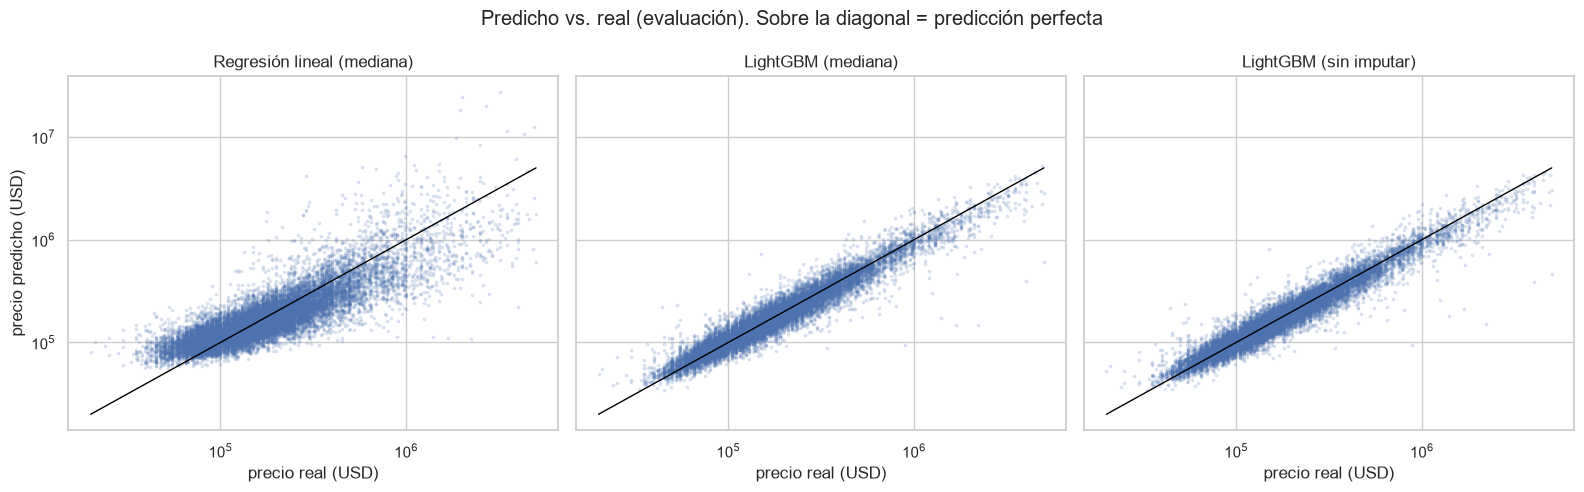

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (nombre, pred_log) in zip(axes, predicciones.items()):
    ax.scatter(precio_test, np.exp(pred_log), s=3, alpha=0.15)
    lims = [20_000, 5_000_000]
    ax.plot(lims, lims, color="black", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(nombre)
    ax.set_xlabel("precio real (USD)")
axes[0].set_ylabel("precio predicho (USD)")
fig.suptitle("Predicho vs. real (evaluación). Sobre la diagonal = predicción perfecta")
plt.tight_layout()
plt.show()


## 5. Variables que más pesan en LightGBM


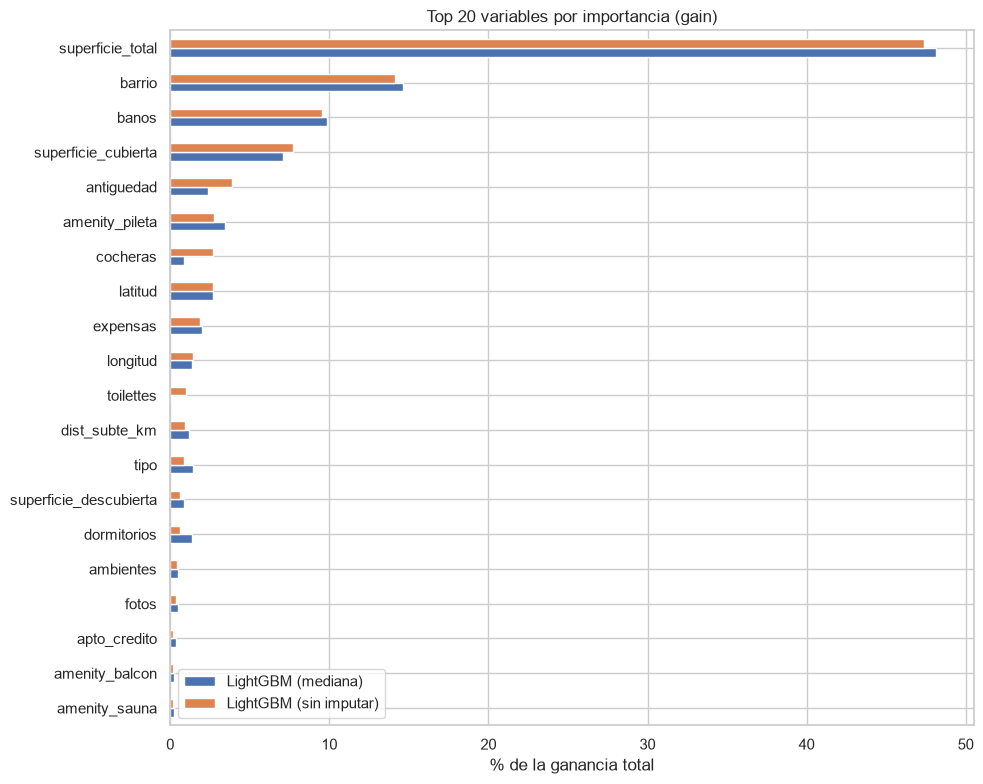

In [9]:
importancias = pd.DataFrame(
    {
        nombre: pd.Series(m.booster_.feature_importance(importance_type="gain"), index=m.feature_name_)
        for nombre, m in modelos_lgb.items()
    }
)
importancias = importancias.div(importancias.sum()).mul(100).sort_values("LightGBM (sin imputar)", ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
importancias.head(20).iloc[::-1].plot.barh(ax=ax)
ax.set_xlabel("% de la ganancia total")
ax.set_title("Top 20 variables por importancia (gain)")
plt.tight_layout()
plt.show()


## 6. Cómo leer los resultados

- **Error % mediano**: para el aviso típico, cuánto se aleja la predicción del precio publicado.
- **MAE (USD)**: error promedio en dólares; lo empujan las propiedades caras.
- **R² log(precio)**: qué parte de la variación (en escala log) explica el modelo.
- La comparación entre los dos LightGBM aísla el efecto de imputar: si el modelo sin imputar
  gana, el hecho de que un dato **falte** también informa sobre el precio (por ejemplo,
  avisos que no declaran antigüedad o cocheras).
- La regresión lineal es la baseline: supone efectos aditivos en log-precio y no capta
  interacciones como "superficie grande en Puerto Madero".
